# LAB 09 — Bias, Variance and Imbalanced Data
Name: Yasir Ali
Student ID: 023-24-0215
Section:BSCS-V (SECTION G)
GitHub: https://github.com/faaniyasirr/ML-Labs
Kaggle: https://www.kaggle.com/code/yasirali110/
Dataset: Stroke Prediction Dataset (Kaggle)
Dataset Source: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset



---
# Part 0 — Setup and the Data
Load the CSV, inspect it, clean it, split 80/20 (stratified), impute and scale using the training set only.

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

SEED = 42
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
plt.rcParams["figure.dpi"] = 100

In [2]:
# --- Load (works in Colab/Jupyter: tries a few common locations) ---
candidates = ["healthcare-dataset-stroke-data.csv", "healthcare-dataset-stroke-data_1.csv",
              "/content/healthcare-dataset-stroke-data.csv",
              "/mnt/user-data/uploads/healthcare-dataset-stroke-data_1.csv"]
path = next(p for p in candidates if os.path.exists(p))
df = pd.read_csv(path)

print("Shape:", df.shape)
print("\nColumns with missing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nGender value counts:\n", df["gender"].value_counts())
vc = df["stroke"].value_counts()
print("\nStroke = 0: %d (%.2f%%)   Stroke = 1: %d (%.2f%%)" % (vc[0], 100*vc[0]/len(df), vc[1], 100*vc[1]/len(df)))

Shape: (5110, 12)

Columns with missing values:
 bmi    201
dtype: int64

Gender value counts:
 gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Stroke = 0: 4861 (95.13%)   Stroke = 1: 249 (4.87%)


In [3]:
# --- Clean ---
data = df.drop(columns=["id"])                       # identifier carries no medical information
data = data[data["gender"] != "Other"].reset_index(drop=True)   # only 1 row: cannot be learned or tested
cat_cols = data.select_dtypes(include=["object", "string"]).columns.tolist()
data = pd.get_dummies(data, columns=cat_cols, drop_first=True, dtype=int)

X = data.drop(columns="stroke")
y = data["stroke"]
print("Encoded feature count:", X.shape[1])

# --- Split 80/20 stratified ---
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)

# --- Median imputation learned from TRAIN only ---
bmi_median = X_train["bmi"].median()
X_train = X_train.fillna({"bmi": bmi_median}).copy()
X_test  = X_test.fillna({"bmi": bmi_median}).copy()
print("Train median bmi used for filling:", round(bmi_median, 2), "| NaNs left:", X_train.isna().sum().sum() + X_test.isna().sum().sum())

# --- Scaled copy (scaler fitted on TRAIN only) for Logistic Regression ---
scaler = StandardScaler().fit(X_train)
Xs_train = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
Xs_test  = pd.DataFrame(scaler.transform(X_test),  columns=X.columns, index=X_test.index)

print("\nTrain rows:", len(X_train), "| strokes in train:", int(y_train.sum()), "(%.2f%%)" % (100*y_train.mean()))
print("Test  rows:", len(X_test),  "| strokes in test :", int(y_test.sum()),  "(%.2f%%)" % (100*y_test.mean()))

Encoded feature count: 15
Train median bmi used for filling: 28.1 | NaNs left: 0

Train rows: 4087 | strokes in train: 199 (4.87%)
Test  rows: 1022 | strokes in test : 50 (4.89%)


### Interpretation and Question (a)
**Data facts.** The file has 5,110 rows and 12 columns. Only `bmi` has missing values (201). `gender` has Female 2,994, Male 2,115 and **Other = 1**; this single row was removed because one row cannot be learned, and if it landed in the test set it could never be learned from. After cleaning there are 5,109 patients and 15 encoded features. The `id` column was dropped because it is only an identifier.

**(a) How imbalanced is the data?** Only 249 of 5,110 patients (4.87%) had a stroke against 4,861 (95.13%) who did not — roughly 1 stroke for every 20 healthy patients. I used `stratify=y` so that the train and test sets keep the same stroke rate (4.87% in train, 4.89% in test). Without it, a random split could put far fewer (or more) strokes in the test set by chance. Even with stratification the test set contains only **50 stroke cases**, so every recall estimate is coarse: one patient changes recall by 2 percentage points (1/50), and any metric computed on the minority class has a wide error bar. With a really unlucky split (say 20 strokes) the metrics could be almost meaningless.

---
# Part 1 — The Accuracy Trap
Compare a model that never predicts stroke with a default Logistic Regression, using six metrics. `evaluate()` is the helper that is re-used for the rest of the lab.

                               Accuracy  Precision  Recall     F1  ROC AUC  PR AUC
Always-majority baseline         0.9511     0.0000  0.0000 0.0000   0.5000  0.0489
Logistic Regression (default)    0.9521     1.0000  0.0200 0.0392   0.8394  0.2692

Confusion matrix (rows = true, cols = predicted):
 [[972   0]
 [ 49   1]]


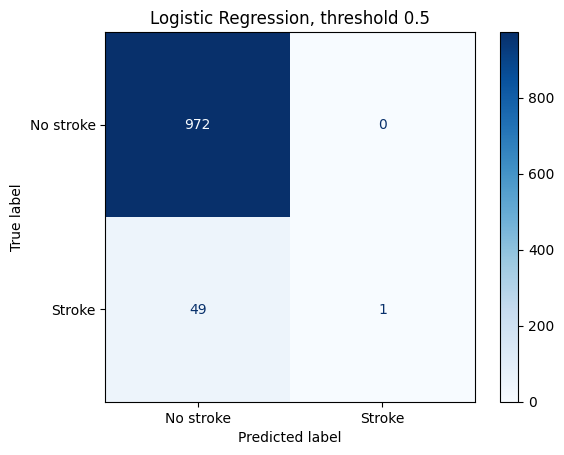

In [4]:
def evaluate(model, Xtr, ytr, Xte, yte, fit=True, threshold=0.5):
    """Fit (optional) and return the six metrics on the test set. Hard labels use `threshold`."""
    if fit:
        model.fit(Xtr, ytr)
    proba = model.predict_proba(Xte)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"Accuracy": accuracy_score(yte, pred),
            "Precision": precision_score(yte, pred, zero_division=0),
            "Recall": recall_score(yte, pred, zero_division=0),
            "F1": f1_score(yte, pred, zero_division=0),
            "ROC AUC": roc_auc_score(yte, proba),
            "PR AUC": average_precision_score(yte, proba)}

dummy = DummyClassifier(strategy="most_frequent")
res_dummy = evaluate(dummy, Xs_train, y_train, Xs_test, y_test)
lr = LogisticRegression(max_iter=1000, random_state=SEED)
res_lr = evaluate(lr, Xs_train, y_train, Xs_test, y_test)

part1 = pd.DataFrame({"Always-majority baseline": res_dummy, "Logistic Regression (default)": res_lr}).T
print(part1)

cm = confusion_matrix(y_test, lr.predict(Xs_test))
print("\nConfusion matrix (rows = true, cols = predicted):\n", cm)
ConfusionMatrixDisplay(cm, display_labels=["No stroke", "Stroke"]).plot(cmap="Blues")
plt.title("Logistic Regression, threshold 0.5"); plt.show()

### Interpretation and Questions
The table shows the always-"no stroke" baseline reaches **accuracy 0.9511** without detecting a single stroke (recall 0, ROC AUC exactly 0.5, PR AUC 0.0489 = the stroke rate). The default Logistic Regression reaches **accuracy 0.9521**, only 0.1 percentage points higher (that is a single extra patient). Its confusion matrix is `[[972, 0], [49, 1]]`: it found just **1 of 50** strokes (recall 0.02, F1 0.039).

**(a) Accuracy comparison.** Both models are ~95% accurate, so accuracy cannot tell a useless model from a slightly better one. When 95% of patients are healthy, "always say healthy" already scores 95%. High accuracy here is produced by the class balance, not by learning.

**(b) False negatives and which numbers to trust.** A false negative is a patient who will have/has a stroke but is told they are fine — they miss early prevention and treatment, which is the most expensive error for the hospital. Logistic Regression made 49 of them out of 50 strokes. The precision of 1.000 is not impressive: it is based on a single positive prediction. I would trust **recall** (0.02, shows the failure), **PR AUC** (0.269 vs no-skill 0.049), **ROC AUC** (0.839 — the model *ranks* patients reasonably) and **F1** instead of accuracy. The gap between the good ROC AUC and the terrible recall suggests the problem is the 0.5 threshold, which is studied in Part 3.

---
# Part 2 — Underfitting, Overfitting, Bias and Variance
A Decision Tree whose `max_depth` runs from 1 to unlimited. The score from now on is ROC AUC. All CV is 5-fold stratified on the training data only.

max_depth  Train AUC  CV AUC
        1     0.7171  0.7317
        2     0.8208  0.8168
        3     0.8375  0.8161
        4     0.8580  0.8180
        5     0.8758  0.7921
        6     0.9026  0.7585
        7     0.9276  0.7385
        8     0.9494  0.7138
        9     0.9678  0.6812
       10     0.9808  0.6414
       11     0.9910  0.6108
       12     0.9959  0.6126
       13     0.9985  0.5955
       14     0.9996  0.5889
       15     0.9999  0.5779
     None     1.0000  0.5644

Best depth by CV AUC: 4 | CV AUC = 0.8180


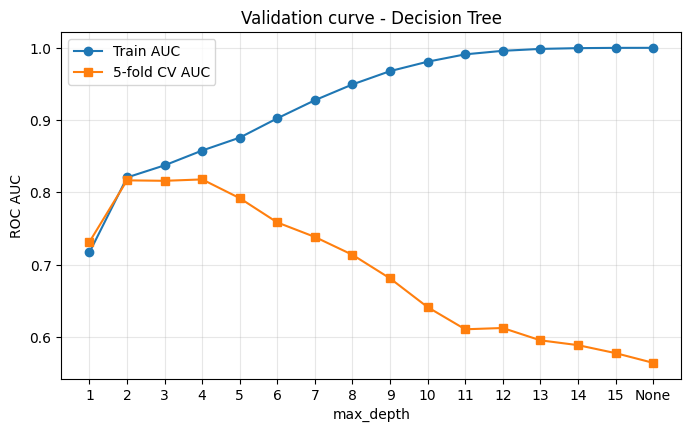

In [5]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
depths = list(range(1, 16)) + [None]
rows = []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    tree.fit(X_train, y_train)
    tr_auc = roc_auc_score(y_train, tree.predict_proba(X_train)[:, 1])
    cv_auc = cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=SEED), X_train, y_train,
                             cv=skf, scoring="roc_auc").mean()
    rows.append({"max_depth": "None" if d is None else d, "Train AUC": tr_auc, "CV AUC": cv_auc})
vc_table = pd.DataFrame(rows)
print(vc_table.to_string(index=False))

best = vc_table.loc[vc_table["CV AUC"].idxmax()]
print("\nBest depth by CV AUC:", best["max_depth"], "| CV AUC = %.4f" % best["CV AUC"])

xs = np.arange(len(vc_table))
plt.figure(figsize=(8, 4.5))
plt.plot(xs, vc_table["Train AUC"], "o-", label="Train AUC")
plt.plot(xs, vc_table["CV AUC"], "s-", label="5-fold CV AUC")
plt.xticks(xs, vc_table["max_depth"].astype(str))
plt.xlabel("max_depth"); plt.ylabel("ROC AUC"); plt.title("Validation curve - Decision Tree")
plt.legend(); plt.grid(alpha=.3); plt.show()

**Validation-curve interpretation.** Train AUC rises steadily with depth until it reaches 1.000 for an unlimited tree (the tree memorises the training set). CV AUC rises from 0.732 (depth 1) to a peak of **0.818 at depth 4**, then falls steadily to 0.564 for an unlimited tree — barely better than random guessing. The best depth by CV AUC is **4**.

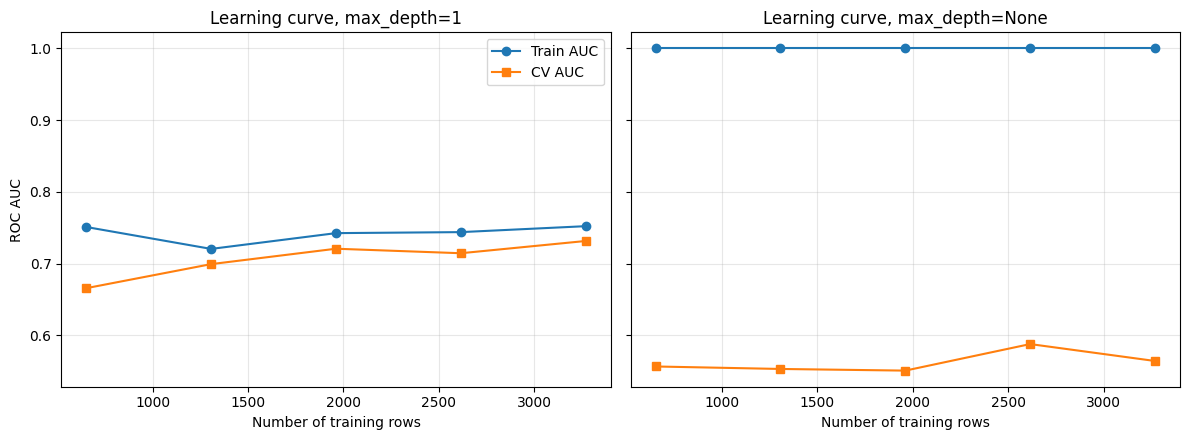

max_depth=1
 rows  train     cv
  653 0.7512 0.6659
 1307 0.7206 0.6994
 1961 0.7426 0.7209
 2615 0.7440 0.7146
 3269 0.7523 0.7317

max_depth=None
 rows  train     cv
  653 1.0000 0.5568
 1307 1.0000 0.5533
 1961 1.0000 0.5510
 2615 1.0000 0.5880
 3269 1.0000 0.5644



In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
lc_summary = {}
for ax, d in zip(axes, [1, None]):
    sizes, tr_sc, va_sc = learning_curve(DecisionTreeClassifier(max_depth=d, random_state=SEED), X_train, y_train,
                                         train_sizes=np.linspace(0.2, 1.0, 5), cv=skf, scoring="roc_auc", random_state=SEED, shuffle=True)
    ax.plot(sizes, tr_sc.mean(axis=1), "o-", label="Train AUC")
    ax.plot(sizes, va_sc.mean(axis=1), "s-", label="CV AUC")
    ax.set_title(f"Learning curve, max_depth={d}"); ax.set_xlabel("Number of training rows"); ax.grid(alpha=.3)
    lc_summary[str(d)] = pd.DataFrame({"rows": sizes, "train": tr_sc.mean(axis=1), "cv": va_sc.mean(axis=1)})
axes[0].set_ylabel("ROC AUC"); axes[0].legend(); plt.tight_layout(); plt.show()
for k, v in lc_summary.items():
    print(f"max_depth={k}"); print(v.to_string(index=False)); print()

**Learning-curve interpretation.** For `max_depth=1` the train AUC (~0.72–0.75) and CV AUC (0.67 → 0.73) both stay low and get close to each other as rows are added: a small gap and a low plateau. For `max_depth=None` the train AUC is exactly 1.000 at every size, while the CV AUC stays at 0.55–0.59 whatever the data size: a huge, persistent gap (~0.43).

In [7]:
rng = np.random.default_rng(SEED)
N_BOOT = 40
var_rows = []
for d in [1, 3, None]:
    probs = np.zeros((N_BOOT, len(X_test)))
    aucs = []
    for b in range(N_BOOT):
        idx = rng.choice(len(X_train), len(X_train), replace=True)
        t = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_train.iloc[idx], y_train.iloc[idx])
        probs[b] = t.predict_proba(X_test)[:, 1]
        aucs.append(roc_auc_score(y_test, probs[b]))
    var_rows.append({"max_depth": "None" if d is None else d,
                     "Mean prediction variance": probs.var(axis=0).mean(),
                     "Mean single-tree test AUC": np.mean(aucs),
                     "Std of single-tree AUC": np.std(aucs),
                     "AUC of averaged prediction": roc_auc_score(y_test, probs.mean(axis=0))})
var_table = pd.DataFrame(var_rows)
print(var_table.to_string(index=False))

max_depth  Mean prediction variance  Mean single-tree test AUC  Std of single-tree AUC  AUC of averaged prediction
        1                    0.0007                     0.7623                  0.0161                      0.8132
        3                    0.0017                     0.7964                  0.0117                      0.8343
     None                    0.0420                     0.5552                  0.0261                      0.7566


**Variance-table interpretation.** The mean variance of a patient's predicted probability across 40 bootstrap trees grows from 0.0007 (depth 1) to 0.0017 (depth 3) to **0.0420 (depth None)**, about 60 times larger. A single unlimited tree is also much worse on the test set (mean AUC 0.555 vs 0.762 for depth 1 and 0.796 for depth 3) and its AUC fluctuates the most from one bootstrap sample to the next (std 0.026 vs 0.016 and 0.012). Averaging the 40 trees lifts the AUC from 0.555 to **0.757** for the unlimited tree (+0.20), from 0.796 to 0.834 for depth 3 (+0.04) and from 0.762 to 0.813 for depth 1 (+0.05).

### Questions
**(a) Underfit / overfit / choice.** *Underfitting (high bias):* depth 1, with train AUC 0.717 and CV AUC 0.732 — both low and almost equal; the model is too simple to capture the age/glucose/heart-disease patterns. *Good zone:* depths 2–4; at depth 4 train AUC = 0.858 and CV AUC = 0.818. *Overfitting (high variance):* depth 8 onward and especially None, e.g. depth 8 has train 0.949 vs CV 0.714, and depth None has train 1.000 vs CV 0.564. I would choose **depth 4** (best CV AUC, 0.818). Depths 2 and 3 (0.817, 0.816) are within noise of it and simpler, so depth 3 (used later in the lab) is an equally defensible choice.

**(b) Reading learning curves.** *High bias:* train and CV curves are both low and converge to a similar plateau (depth 1: ≈0.75 vs ≈0.73). *High variance:* train score is near perfect but the CV score is far lower, with a large gap (depth None: 1.000 vs 0.56). More rows will **not** fix the high-bias model — the curves have already flattened, so its limit is the model's simplicity (it needs a richer model/features). For the high-variance model more rows should narrow the gap in theory, but in our range the CV AUC barely moves (0.557 → 0.564), so we would need far more data (or regularisation like depth limit, averaging) to benefit.

**(c) Variance vs depth and averaging.** Variance increases strongly with depth (0.0007 → 0.0017 → 0.0420) because a deeper tree fits individual patients, so a small change in the training sample produces very different trees. Averaging 40 trees reduces this variance and increases AUC the most for the unlimited tree (0.555 → 0.757), where variance was the main problem; the gain is smaller for shallow trees whose problem is bias (averaging cannot fix bias). This is exactly what **Random Forest** (Lab 4) does: it trains many deep, low-bias, high-variance trees on bootstrap samples (plus random feature subsets) and averages them, which removes much of the variance. In Part 3 the Random Forest gets test AUC 0.822, far above a single unlimited tree.

**(d) Bias–variance trade-off.** Prediction error comes from *bias* (the model is too simple, systematically wrong) and *variance* (the model is too sensitive to the particular training sample). Making a model more flexible lowers bias but raises variance, so there is a sweet spot. **Depth 1** = high bias, low variance (variance 0.0007, AUC 0.73 on CV: underfit). **Depth 3** = a balance (variance 0.0017, CV AUC 0.816). **Depth None** = low bias, very high variance (0.0420, train AUC 1.0 but CV 0.564: overfit).

---
# Part 3 — ROC, AUC, Precision-Recall and Thresholds

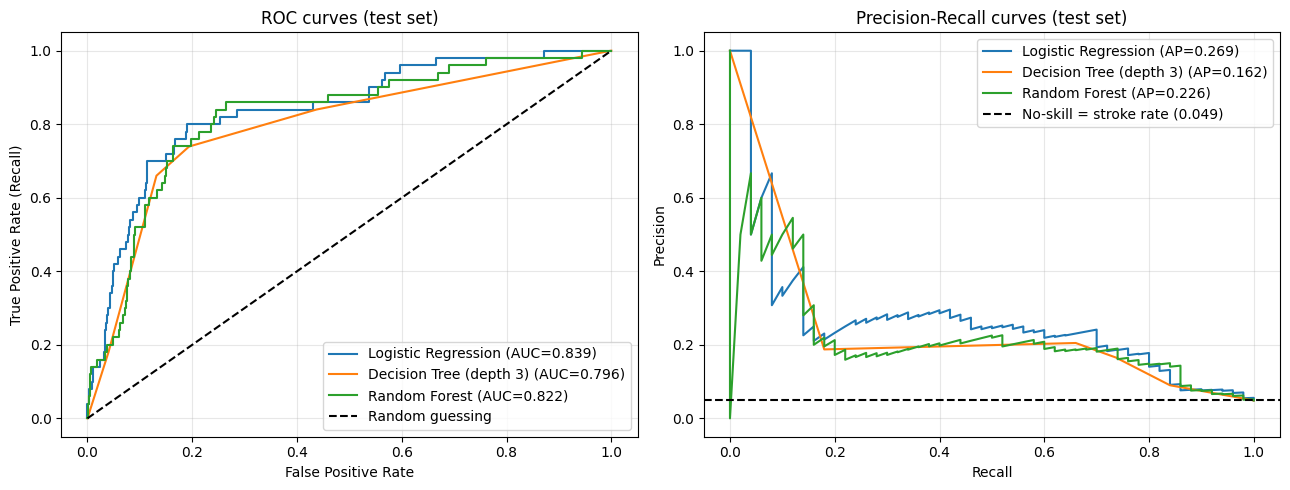

                         ROC AUC  Average precision (PR AUC)
Logistic Regression       0.8394                      0.2692
Decision Tree (depth 3)   0.7956                      0.1621
Random Forest             0.8224                      0.2255
No-skill PR level (stroke rate in test): 0.0489


In [8]:
models3 = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=SEED), Xs_train, Xs_test),
    "Decision Tree (depth 3)": (DecisionTreeClassifier(max_depth=3, random_state=SEED), X_train, X_test),
    "Random Forest": (RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1), X_train, X_test),
}
probas = {}
for name, (m, Xtr, Xte) in models3.items():
    m.fit(Xtr, y_train)
    probas[name] = m.predict_proba(Xte)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Random guessing")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].set_title("ROC curves (test set)"); axes[0].legend(loc="lower right"); axes[0].grid(alpha=.3)

for name, p in probas.items():
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, label=f"{name} (AP={average_precision_score(y_test, p):.3f})")
base_rate = y_test.mean()
axes[1].axhline(base_rate, color="k", ls="--", label=f"No-skill = stroke rate ({base_rate:.3f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-Recall curves (test set)")
axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print(pd.DataFrame({"ROC AUC": {n: roc_auc_score(y_test, p) for n, p in probas.items()},
                    "Average precision (PR AUC)": {n: average_precision_score(y_test, p) for n, p in probas.items()}}))
print("No-skill PR level (stroke rate in test): %.4f" % base_rate)

**Curve interpretation.** Logistic Regression has the best ROC AUC (0.839) and best average precision (0.269), followed by Random Forest (0.822 / 0.226) and the depth-3 tree (0.796 / 0.162). All ROC curves are well above the random diagonal. On the PR plot all models are well above the no-skill line at 0.049 but far from perfect: precision falls quickly as recall rises (at about 80% recall LR's precision is only ~0.13). The simple, low-variance Logistic Regression is competitive with, and here better than, the more flexible models, which is consistent with the small number of strokes (199) available for training.

Chosen threshold (from training OOF): 0.0509
OOF recall at that threshold: 0.804

TEST  recall = 0.820 | precision = 0.135
Confusion matrix (rows = true, cols = predicted):
 [[710 262]
 [  9  41]]
Patients flagged: 303 of 1022 (29.6%) | true strokes caught: 41 | false alarms: 262 | missed strokes: 9


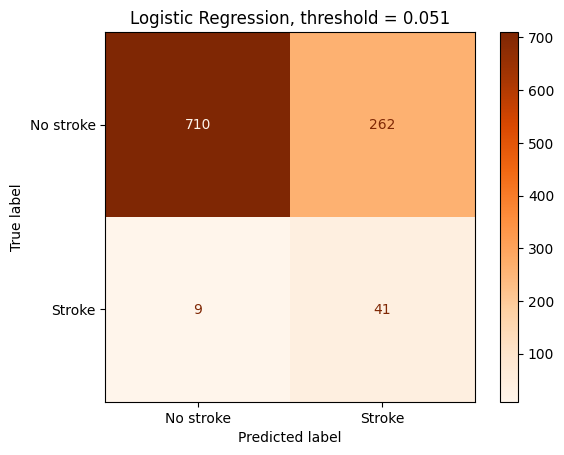

In [9]:
# Out-of-fold probabilities from TRAIN data only. A pipeline keeps the scaler inside each fold (no leakage across folds).
pipe_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))
oof = cross_val_predict(pipe_lr, X_train, y_train, cv=skf, method="predict_proba")[:, 1]

prec_o, rec_o, thr_o = precision_recall_curve(y_train, oof)
ok = rec_o[:-1] >= 0.80                       # recall at each threshold (last PR point has no threshold)
THRESH = thr_o[ok].max()                      # highest threshold that still gives recall >= 0.80 on OOF
print("Chosen threshold (from training OOF): %.4f" % THRESH)
print("OOF recall at that threshold: %.3f" % recall_score(y_train, oof >= THRESH))

# Apply to test set
p_test = probas["Logistic Regression"]
pred_t = (p_test >= THRESH).astype(int)
cm_t = confusion_matrix(y_test, pred_t)
tn, fp, fn, tp = cm_t.ravel()
print("\nTEST  recall = %.3f | precision = %.3f" % (recall_score(y_test, pred_t), precision_score(y_test, pred_t)))
print("Confusion matrix (rows = true, cols = predicted):\n", cm_t)
print("Patients flagged: %d of %d (%.1f%%) | true strokes caught: %d | false alarms: %d | missed strokes: %d"
      % (tp + fp, len(y_test), 100*(tp+fp)/len(y_test), tp, fp, fn))
ConfusionMatrixDisplay(cm_t, display_labels=["No stroke", "Stroke"]).plot(cmap="Oranges")
plt.title(f"Logistic Regression, threshold = {THRESH:.3f}"); plt.show()

**Threshold interpretation.** Using only the training data (5-fold out-of-fold probabilities, scaler inside a pipeline), the highest threshold that gives recall ≥ 0.80 is **0.0509** (OOF recall 0.804) — close to the base rate of 4.9%, far below 0.5. On the test set this gives **recall 0.82 (41 of 50 strokes caught)**, so the training-derived threshold transferred well. The price: **precision 0.135**, **303 patients flagged** (29.6% of the test set), of which **262 are false alarms** and 9 strokes are still missed.

### Questions
**(a) Low recall but ROC AUC 0.84.** AUC measures the *ranking* quality over all possible thresholds: it is the probability that a randomly chosen stroke patient receives a higher score than a randomly chosen healthy patient. Recall in Part 1 was computed at one fixed threshold, 0.5. Because only 4.9% of patients have a stroke, the model's predicted probabilities are small for nearly everybody (most are far below 0.5), so almost nobody crosses 0.5 even though stroke patients are scored higher than healthy ones on average. The ranking is good, the cut-off is wrong; moving the threshold to 0.051 raises recall from 0.02 to 0.82 without retraining.

**(b) ROC or PR?** For this data the **Precision-Recall curve is more informative**. The ROC curve looks good (AUC 0.84) because the false positive rate divides by ~972 healthy patients, so 262 false alarms look like only 27% FPR. The PR curve exposes what the hospital actually experiences: the no-skill line is 0.049, our best model has average precision 0.269 (about 5.5× no-skill, but still low) and precision at 80% recall is only ~0.13. PR curves ignore the many true negatives and so do not hide the imbalance problem.

**(c) Price of higher recall.** *Cost:* 303 patients (29.6%) are flagged, 262 of them are false alarms — about 6.4 false alarms for every stroke caught (precision 0.135) — meaning extra tests, worry and cost. *Acceptable:* a missed stroke can mean death or permanent disability, while a false alarm for a routine screening usually leads to a cheap follow-up (blood pressure, glucose, a doctor visit); catching 41 instead of 1 stroke (recall 0.82 vs 0.02) is a very large benefit. *Not acceptable:* flagging almost a third of all patients may overload the clinic and cause unnecessary tests/treatment with side effects, and if follow-up resources are limited the hospital might prefer a higher threshold (lower recall, higher precision). Because the first step is only screening, I find the trade-off acceptable if the follow-up is cheap.

---
# Part 4 — Undersampling, Oversampling and SMOTE
Logistic Regression uses the scaled data, Random Forest the original data. Resampling is done on the **training set only**; the test set is never touched. Threshold stays at 0.5.

In [10]:
def make_rf(**kw):
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1, **kw)
def make_lr(**kw):
    return LogisticRegression(max_iter=1000, random_state=SEED, **kw)

samplers = {"No resampling": None, "class_weight='balanced'": "cw",
            "Random undersampling": RandomUnderSampler(random_state=SEED),
            "Random oversampling": RandomOverSampler(random_state=SEED),
            "SMOTE": SMOTE(random_state=SEED)}

rows = []
for mname, maker, Xtr, Xte in [("Logistic Regression", make_lr, Xs_train, Xs_test), ("Random Forest", make_rf, X_train, X_test)]:
    for sname, s in samplers.items():
        if s is None:
            Xr, yr, model = Xtr, y_train, maker()
        elif s == "cw":
            Xr, yr, model = Xtr, y_train, maker(class_weight="balanced")
        else:
            Xr, yr = s.fit_resample(Xtr, y_train)          # TRAIN only
            model = maker()
        m = evaluate(model, Xr, yr, Xte, y_test)            # test set untouched
        rows.append({"Model + method": f"{mname} | {sname}", "Train rows": len(Xr), "Train strokes": int(yr.sum()),
                     **{k: m[k] for k in ["Precision", "Recall", "F1", "ROC AUC", "PR AUC"]}})
table4 = pd.DataFrame(rows)
print(table4.to_string(index=False))

                               Model + method  Train rows  Train strokes  Precision  Recall     F1  ROC AUC  PR AUC
          Logistic Regression | No resampling        4087            199     1.0000  0.0200 0.0392   0.8394  0.2692
Logistic Regression | class_weight='balanced'        4087            199     0.1347  0.8000 0.2305   0.8395  0.2595
   Logistic Regression | Random undersampling         398            199     0.1246  0.8200 0.2164   0.8352  0.2338
    Logistic Regression | Random oversampling        7776           3888     0.1333  0.8000 0.2286   0.8385  0.2646
                  Logistic Regression | SMOTE        7776           3888     0.1338  0.8000 0.2292   0.8406  0.2876
                Random Forest | No resampling        4087            199     0.0000  0.0000 0.0000   0.8224  0.2255
      Random Forest | class_weight='balanced'        4087            199     0.2143  0.3000 0.2500   0.8109  0.2088
         Random Forest | Random undersampling         398            199

**Table interpretation.** The Logistic Regression rows all have almost the same ROC AUC (0.835–0.841) while recall jumps from 0.02 to 0.80–0.82 once any rebalancing is used. The Random Forest rows are very different from each other (recall 0.00, 0.30, 0.84, 0.32 and 0.20; ROC AUC between 0.767 and 0.822).

In [11]:
# WRONG ORDER: SMOTE on ALL data first, then split. (bmi imputed with the all-data median here, as there is no train set yet.)
X_all = X.fillna({"bmi": X["bmi"].median()})
X_sm, y_sm = SMOTE(random_state=SEED).fit_resample(X_all, y)
print("After SMOTE on all data:", X_sm.shape, "| strokes:", int(y_sm.sum()))
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(X_sm, y_sm, test_size=0.20, stratify=y_sm, random_state=SEED)
m_wrong = evaluate(make_rf(), Xw_tr, yw_tr, Xw_te, yw_te)
print("Test set of wrong pipeline: %d rows, %d 'strokes' (of which many are synthetic)" % (len(yw_te), yw_te.sum()))

m_right = table4[table4["Model + method"] == "Random Forest | SMOTE"].iloc[0]
cmp = pd.DataFrame([
    {"Pipeline": "WRONG: SMOTE then split", **{k: m_wrong[k] for k in ["Precision", "Recall", "F1", "ROC AUC", "PR AUC"]}},
    {"Pipeline": "CORRECT: split then SMOTE (train only)", **{k: m_right[k] for k in ["Precision", "Recall", "F1", "ROC AUC", "PR AUC"]}},
])
print(cmp.to_string(index=False))

After SMOTE on all data: (9720, 15) | strokes: 4860


Test set of wrong pipeline: 1944 rows, 972 'strokes' (of which many are synthetic)
                              Pipeline  Precision  Recall     F1  ROC AUC  PR AUC
               WRONG: SMOTE then split     0.9290  0.9424 0.9356   0.9811  0.9761
CORRECT: split then SMOTE (train only)     0.1266  0.2000 0.1550   0.7668  0.1187


**Leakage comparison.** Applying SMOTE to all the data first gives apparently excellent numbers (precision 0.929, recall 0.942, ROC AUC 0.981, PR AUC 0.976) compared with the honest pipeline (precision 0.127, recall 0.200, ROC AUC 0.767, PR AUC 0.119).

### Questions
**(a) Logistic Regression: what changed, what did not.** *Changed:* recall rose from 0.02 to 0.80 (balanced weights), 0.82 (undersampling), 0.80 (oversampling) and 0.80 (SMOTE), while precision fell from a meaningless 1.00 (one prediction) to ~0.12–0.13 and F1 rose from 0.04 to ~0.22–0.23. *Not changed:* ROC AUC (0.835–0.841) and PR AUC (0.234–0.288) — the model still ranks patients almost identically. Reason: Logistic Regression is a low-variance linear model with a few coefficients; resampling or reweighting mostly changes the intercept (the prior), which moves all predicted probabilities up. Since the ranking is the same, only the effective threshold changes — exactly the same as moving the threshold in Part 3. Undersampling lost a little (it throws away about 3,700 healthy rows, ROC AUC 0.835, PR AUC 0.234), while SMOTE had the highest PR AUC (0.288) but that gain is small, and probably within noise given 50 test strokes.

**(b) Random Forest vs LR.** No, it reacted differently. For Logistic Regression all four methods give ≈0.80 recall and the same AUC, but for Random Forest the outcome depends strongly on the method: recall was 0.00 with no resampling, 0.84 with undersampling, but only 0.20–0.32 with SMOTE/oversampling, and SMOTE **reduced the ROC AUC to 0.767** (from 0.822) and PR AUC to 0.119 (from 0.226). A possible reason: a flexible forest fits the training set closely. Oversampling by copying (or SMOTE interpolating) gives the trees the same few minority points hundreds of times, so leaves of 5 rows are filled with copies of the same patient — the model memorises these 199 patients (overfits, high variance), and those regions do not generalise to new patients, so on the test set few strokes get a high probability. Undersampling doesn't have duplicates and moves the forest's probabilities up, giving high recall (0.84) at low precision (0.105).

**(c) Wrong order vs correct order.** The wrong order looks like precision 0.93 / recall 0.94 / AUC 0.98, but those numbers are fake. SMOTE was run before the split, so (1) the synthetic stroke patients were interpolated between real strokes that later fall in both the train and the test sets — a synthetic test "patient" sits right next to (or is an interpolation of) real patients in the training set, and the information leaks from the test records into the training records and the other way round; (2) the test set is no longer real: about half of it is synthetic and balanced 50/50 (972 "strokes" out of 1,944), so the evaluation no longer reflects the 4.9% stroke rate the hospital faces, and the random forest can simply recognise near-duplicates. The correct pipeline gives recall 0.20 and PR AUC 0.12. The wrong-order result can not be trusted because it measures memorisation of neighbours, not generalisation to new patients.

**(d) My choice.** I would choose **`class_weight='balanced'` with Logistic Regression** (or, equally simple, keep default training and move the decision threshold, as in Part 3). It reaches recall 0.80 with the same ROC AUC (0.8395) as the original, requires no extra library, does not duplicate or invent patients, does not change the size of the data, and has no leakage risk. Undersampling discards 90% of the training rows and was no better; oversampling/SMOTE doubles the data size and training time and did not improve ROC AUC; SMOTE also brings the risk of the wrong-order mistake, and (Part 5.3) amplifies noise.

---
# Part 5 — Noisy Data
Training data is damaged on purpose; the test set stays clean. Models: Logistic Regression (scaler fitted on the training data it sees), Decision Tree (depth 3), Decision Tree (no limit) and Random Forest. Metric: test ROC AUC. Label-noise and feature-noise rows are averages over 5 random repeats (1 for no noise).

In [12]:
def flip_labels(y, frac, rng):
    y_new = np.array(y, copy=True)
    if frac > 0:
        idx = rng.choice(len(y_new), int(round(frac * len(y_new))), replace=False)
        y_new[idx] = 1 - y_new[idx]
    return y_new

def test_auc_models(Xtr, ytr, Xte, scale_for_lr=True):
    """Fit the four models on (possibly noisy) training data; return test ROC AUC for each.
    If scale_for_lr, the scaler for LR is fitted on the given (noisy) training data."""
    sc = StandardScaler().fit(Xtr)
    out = {}
    lr_m = make_lr().fit(sc.transform(Xtr), ytr)
    out["Logistic Regression"] = roc_auc_score(y_test, lr_m.predict_proba(sc.transform(Xte))[:, 1])
    for nm, mk in [("Tree depth 3", lambda: DecisionTreeClassifier(max_depth=3, random_state=SEED)),
                   ("Tree no limit", lambda: DecisionTreeClassifier(random_state=SEED)),
                   ("Random Forest", make_rf)]:
        out[nm] = roc_auc_score(y_test, mk().fit(Xtr, ytr).predict_proba(Xte)[:, 1])
    return out

                Logistic Regression  Tree depth 3  Tree no limit  Random Forest
Noise fraction                                                                 
0.0000                       0.8394        0.7956         0.5797         0.8224
0.0500                       0.8242        0.7933         0.5298         0.7997
0.1000                       0.8234        0.7955         0.5482         0.7785
0.2000                       0.7920        0.7299         0.5492         0.7146


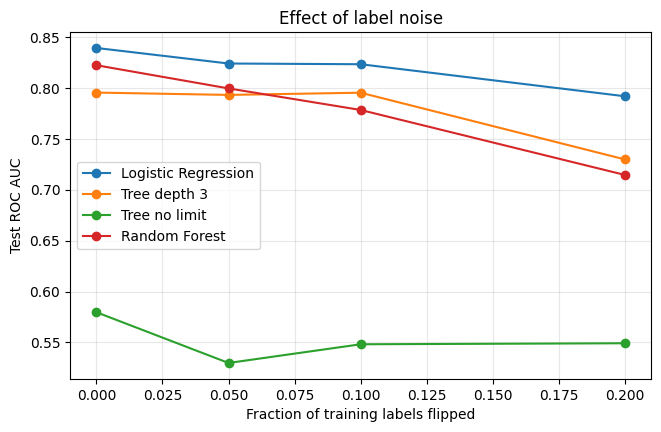

In [13]:
rng = np.random.default_rng(SEED)
label_rows = []
for frac in [0, 0.05, 0.10, 0.20]:
    reps = 1 if frac == 0 else 5
    res = [test_auc_models(X_train, pd.Series(flip_labels(y_train, frac, rng)), X_test) for _ in range(reps)]
    label_rows.append({"Noise fraction": frac, **pd.DataFrame(res).mean().to_dict()})
label_table = pd.DataFrame(label_rows).set_index("Noise fraction")
print(label_table)

label_table.plot(marker="o", figsize=(7.5, 4.5))
plt.xlabel("Fraction of training labels flipped"); plt.ylabel("Test ROC AUC"); plt.title("Effect of label noise")
plt.grid(alpha=.3); plt.show()

**Label-noise interpretation.** With no noise the AUCs are LR 0.839, tree-3 0.796, unlimited tree 0.580, forest 0.822. At 20% flipped labels they fall to 0.792, 0.730, 0.549 and 0.715. The Random Forest declines continuously (0.822 → 0.800 → 0.779 → 0.715); LR declines the least among the good models (0.839 → 0.792).

             Logistic Regression  Tree depth 3  Tree no limit  Random Forest
Noise level                                                                 
0.0000                    0.8394        0.7956         0.5797         0.8224
0.5000                    0.8326        0.8121         0.5661         0.8159
1.0000                    0.8077        0.7703         0.5371         0.7851
2.0000                    0.7637        0.6853         0.5200         0.7358


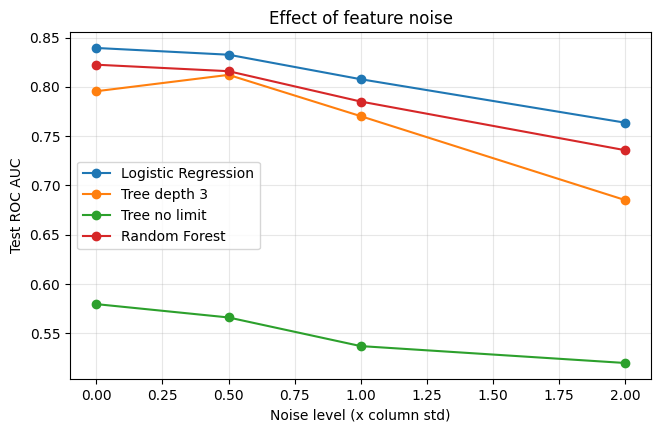

In [14]:
rng = np.random.default_rng(SEED)
noisy_cols = ["age", "avg_glucose_level", "bmi"]
stds = X_train[noisy_cols].std()
feat_rows = []
for level in [0, 0.5, 1, 2]:
    reps = 1 if level == 0 else 5
    res = []
    for _ in range(reps):
        Xn = X_train.copy()
        for c in noisy_cols:
            Xn[c] = Xn[c] + rng.normal(size=len(Xn)) * stds[c] * level
        res.append(test_auc_models(Xn, y_train, X_test))
    feat_rows.append({"Noise level": level, **pd.DataFrame(res).mean().to_dict()})
feat_table = pd.DataFrame(feat_rows).set_index("Noise level")
print(feat_table)

feat_table.plot(marker="o", figsize=(7.5, 4.5))
plt.xlabel("Noise level (x column std)"); plt.ylabel("Test ROC AUC"); plt.title("Effect of feature noise")
plt.grid(alpha=.3); plt.show()

In [15]:
drop = pd.DataFrame({"Label noise 20% (drop in AUC)": label_table.iloc[0] - label_table.iloc[-1],
                     "Feature noise level 2 (drop in AUC)": feat_table.iloc[0] - feat_table.iloc[-1]})
print(drop)
print("\nMean drop over the four models:\n", drop.mean())
print("\nAUC std of a single unlimited tree over bootstrap resamples (Part 2.3): %.4f" % var_table.iloc[2]["Std of single-tree AUC"])

                     Label noise 20% (drop in AUC)  Feature noise level 2 (drop in AUC)
Logistic Regression                         0.0474                               0.0757
Tree depth 3                                0.0657                               0.1103
Tree no limit                               0.0305                               0.0597
Random Forest                               0.1078                               0.0866

Mean drop over the four models:
 Label noise 20% (drop in AUC)         0.0629
Feature noise level 2 (drop in AUC)   0.0831
dtype: float64

AUC std of a single unlimited tree over bootstrap resamples (Part 2.3): 0.0261


**Feature-noise interpretation.** Small noise (level 0.5) hardly matters (LR 0.833, forest 0.816; the depth-3 tree even scores a little higher, 0.812 vs 0.796, which is random fluctuation). At level 2 — noise with twice the standard deviation of the column — AUC falls to LR 0.764, tree-3 0.685, forest 0.736. The unlimited tree is near chance (0.52–0.58) at all levels.

In [16]:
rng = np.random.default_rng(SEED)
rows = []
for draw in range(3):
    y_noisy = pd.Series(flip_labels(y_train, 0.10, rng), index=y_train.index)
    for mname, maker, Xtr, Xte in [("Logistic Regression", make_lr, Xs_train, Xs_test), ("Random Forest", make_rf, X_train, X_test)]:
        for use_smote in [False, True]:
            if use_smote:
                Xr, yr = SMOTE(random_state=SEED).fit_resample(Xtr, y_noisy)   # SMOTE applied AFTER the noise
            else:
                Xr, yr = Xtr, y_noisy
            m = evaluate(maker(), Xr, yr, Xte, y_test)
            rows.append({"Model": mname, "SMOTE": "with SMOTE" if use_smote else "without", "PR AUC": m["PR AUC"], "ROC AUC": m["ROC AUC"]})
smote_noise = pd.DataFrame(rows).groupby(["Model", "SMOTE"]).mean()
print("Mean over 3 random 10% label flips (test set untouched):")
print(smote_noise)

Mean over 3 random 10% label flips (test set untouched):
                                PR AUC  ROC AUC
Model               SMOTE                      
Logistic Regression with SMOTE  0.2269   0.8051
                    without     0.2321   0.8105
Random Forest       with SMOTE  0.0610   0.5943
                    without     0.1827   0.7431


**SMOTE with 10% noisy labels (mean of 3 draws).**

| Model | PR AUC without SMOTE | PR AUC with SMOTE | ROC AUC without | ROC AUC with |
|---|---|---|---|---|
| Logistic Regression | 0.232 | 0.227 | 0.811 | 0.805 |
| Random Forest | 0.183 | 0.061 | 0.743 | 0.594 |

SMOTE made Logistic Regression only slightly worse (−0.005 PR AUC, −0.005 ROC AUC) but severely damaged the Random Forest (PR AUC 0.183 → 0.061, ROC AUC 0.743 → 0.594, close to guessing).

### Questions
**(a) Most damaged / most stable.** In terms of the AUC drop between the clean and the highest noise level, the model *most damaged by label noise* is the **Random Forest** (0.822 → 0.715, −0.108) and by feature noise the **depth-3 tree** (0.796 → 0.685, −0.110; the forest loses 0.087). The *most stable* is **Logistic Regression** (−0.047 for label noise, −0.076 for feature noise) and it keeps the highest AUC under both kinds of noise (0.792 and 0.764). This follows Part 2: flexible, high-variance models (forest leaves of 5 rows, deep trees) fit the wrong labels/noisy values and learn them as if they were signal, whereas a model with few parameters (LR with 15 coefficients, high bias, low variance) averages the noise out. The unlimited tree has the smallest drops (−0.031, −0.060) but that is misleading: it was already overfitted and almost at chance (0.580 clean AUC; its bootstrap AUC fluctuation alone is ±0.026), so there was little left to lose. (Note that the forest's bagging averages out *variance* but cannot ignore wrong labels, which behave like consistent signal in the leaves.)

**(b) Label noise or feature noise?** The two scales are not exactly comparable, but at their maximum levels averaged over the four models the AUC drops 0.083 for feature noise (level 2) and 0.063 for label noise (20%), so feature noise hurt more for LR and tree-3, and label noise hurt more for the forest. Reason: the signal in this dataset lives in only a few numeric columns (especially `age` and `avg_glucose_level`); noise with 2× std completely swamps `age`, destroying the best predictor for every model. Label noise, in contrast, is random, so with LR it just weakens the estimated coefficients (all the labels are wrong at random, which on average dilutes but does not reverse the signal) — except that with only 199 true strokes, flipping labels creates many false strokes among 4,000 healthy patients.

**(c) SMOTE and noisy labels.** For LR, SMOTE has almost no effect (−0.005); the model is stable and had only a probability shift. For the Random Forest it was very harmful (PR AUC 0.183 → 0.061, ROC AUC 0.743 → 0.594). SMOTE amplifies label noise because it treats every point labelled "stroke" as a trustworthy minority neighbour and creates new points on lines between them. With a 10% flip, about 390 healthy patients become false "strokes" while about 20 real strokes are lost, so roughly two thirds of the training "stroke" class (568 rows, only ~179 real) is wrong. SMOTE interpolates between these points, so it spreads the false labels across large regions of the feature space (synthetic points in the middle of the healthy population and between real and fake strokes), manufacturing thousands of confidently wrong examples; a flexible model such as the Random Forest then memorises them.

---
# Part 6 — Final Decision and Conclusion
**Final approach:** Logistic Regression (scaled features, default training) with the decision threshold learned from the training out-of-fold probabilities (recall target ≥ 0.80). Compared with the default threshold 0.5 on the untouched test set.

In [17]:
# Final choice: Logistic Regression (class-prior unchanged) + decision threshold learned from TRAIN out-of-fold probabilities
final_lr = make_lr().fit(Xs_train, y_train)
fin = {}
for label, thr in [("Default threshold 0.5", 0.5), (f"Chosen threshold {THRESH:.3f}", THRESH)]:
    m = evaluate(final_lr, Xs_train, y_train, Xs_test, y_test, fit=False, threshold=thr)
    pred = (final_lr.predict_proba(Xs_test)[:, 1] >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    fin[label] = {"Precision": m["Precision"], "Recall": m["Recall"], "F1": m["F1"], "Flagged patients": tp + fp,
                  "Strokes caught": tp, "False alarms": fp, "Missed strokes": fn}
final_table = pd.DataFrame(fin).T
print(final_table.to_string())

                        Precision  Recall     F1  Flagged patients  Strokes caught  False alarms  Missed strokes
Default threshold 0.5      1.0000  0.0200 0.0392            1.0000          1.0000        0.0000         49.0000
Chosen threshold 0.051     0.1353  0.8200 0.2323          303.0000         41.0000      262.0000          9.0000


**Table interpretation.** At threshold 0.5 the model flags one patient and finds 1 of 50 strokes (49 missed, 0 false alarms). With the chosen threshold of 0.051 it flags 303 patients: 41 strokes caught, 9 missed, 262 false alarms. Precision falls from 1.00 (based on one prediction) to 0.135, recall rises from 0.02 to 0.82 and F1 from 0.039 to 0.232.

### Executive Summary
I chose **Logistic Regression on scaled features with a lowered decision threshold of 0.051** (instead of 0.5). The threshold was selected on out-of-fold predictions from the training set so as to reach at least 80% recall. On the untouched test set it detects **41 of 50 strokes (recall 0.82)** with **precision 0.135** (F1 0.232), compared with recall 0.02 at the default threshold. The price is 303 flagged patients (29.6% of those tested), 262 of them false alarms (about 6 false alarms per stroke found), and 9 missed strokes. Logistic Regression was preferred because it had the best ROC AUC (0.839) and PR AUC (0.269) of the compared models, it is the most stable under noisy data (Part 5) and it needs no resampling (SMOTE gave no benefit and was harmful for forests). Leakage was avoided by splitting first, learning the median imputer, the scaler and the threshold from the training data only (scaler inside a pipeline for cross-validation), resampling only the training set, and never touching the test set. **Limitations:** the test set contains only 50 strokes, so recall 0.82 has a margin of roughly ±10 percentage points (41/50 could be 0.70–0.90 in another sample); the threshold itself depends on a single OOF estimate and on the 80% recall target, which is a policy choice that the hospital must set based on the cost of follow-up; the dataset is a single Kaggle sample without external validation.

### Final Reflection
**(a) Most surprising result.** The most surprising results were that a model with 95.2% accuracy found only 1 of 50 strokes, and that the same model gave recall 0.82 just by changing the threshold from 0.5 to 0.051 without retraining — and that SMOTE-before-split produced an AUC of 0.98 while the honest pipeline was 0.77. A close second: unlimited tree CV AUC (0.56) is barely better than guessing.

**(b) With one more hour.** I would (1) repeat the experiments with repeated stratified cross-validation (or many different seeds) to get confidence intervals, since the test set has only 50 strokes; (2) tune a regularised model such as gradient boosting or LR with `C` tuned by CV, and calibrate its probabilities; (3) choose the threshold using an explicit cost for a false negative vs a false alarm instead of a fixed 80% recall target; (4) test SMOTE variants (e.g. Borderline-SMOTE, SMOTE-ENN) for noisy data.